<a href="https://colab.research.google.com/github/iberil/leukemia-gene-expression-analysis/blob/main/Golub_ALL_AML_EDA_and_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

In [7]:
df_act = pd.read_csv("https://raw.githubusercontent.com/iberil/leukemia-gene-expression-analysis/refs/heads/main/data/actual.csv")
df_train = pd.read_csv("https://raw.githubusercontent.com/iberil/leukemia-gene-expression-analysis/refs/heads/main/data/data_set_ALL_AML_train.csv")
df_ind = pd.read_csv("https://raw.githubusercontent.com/iberil/leukemia-gene-expression-analysis/refs/heads/main/data/data_set_ALL_AML_independent.csv")

df_act["numeric_label"]= df_act["cancer"].map({"ALL":0, "AML":1})

print("Etiket Dağılımı: ")
print(df_act['cancer'].value_counts())

Etiket Dağılımı: 
cancer
ALL    47
AML    25
Name: count, dtype: int64


In [13]:
df_train_cleaned=df_train.loc[:,~df_train.columns.str.contains("call")]
df_ind_cleaned=df_ind.loc[:,~df_ind.columns.str.contains("call")]

df_ind_cleaned.head(5)

,Gene Description,Gene Accession Number,39,40,42,47,48,49,41,43,...,54,57,58,60,61,65,66,63,64,62
0,AFFX-BioB-5_at (endogenous control),AFFX-BioB-5_at,-342,-87,22,-243,-130,-256,-62,86,...,-90,-137,-157,-172,-47,-62,-58,-161,-48,-176
1,AFFX-BioB-M_at (endogenous control),AFFX-BioB-M_at,-200,-248,-153,-218,-177,-249,-23,-36,...,-87,-51,-370,-122,-442,-198,-217,-215,-531,-284
2,AFFX-BioB-3_at (endogenous control),AFFX-BioB-3_at,41,262,17,-163,-28,-410,-7,-141,...,102,-82,-77,38,-21,-5,63,-46,-124,-81
3,AFFX-BioC-5_at (endogenous control),AFFX-BioC-5_at,328,295,276,182,266,24,142,252,...,319,178,340,31,396,141,95,146,431,9
4,AFFX-BioC-3_at (endogenous control),AFFX-BioC-3_at,-224,-226,-211,-289,-170,-535,-233,-201,...,-283,-135,-438,-201,-351,-256,-191,-172,-496,-294


In [14]:
# Önce gen isimlerini index yapıp veriyi transpoze edelim (hastalar satır, genler sütun olsun)
X_train = df_train_cleaned.set_index('Gene Accession Number').drop(columns=['Gene Description']).T

# Index'i (hasta numaralarını) sayısal tipe çevirelim ki actual.csv ile eşleşebilsin
X_train.index = X_train.index.astype(int)

# actual.csv ile hasta numarası üzerinden birleştirelim
train_final = X_train.merge(df_act[['patient', 'numeric_label']], left_index=True, right_on='patient')


In [15]:
print("Train veri seti boyutu (Satır, Sütun):", train_final.shape)

Train veri seti boyutu (Satır, Sütun): (38, 7131)


In [16]:
print("Eğitim seti etiket dağılımı:")
print(train_final['numeric_label'].value_counts())
# 0 (ALL) -> 27, 1 (AML) -> 11 çıkmalı.

Eğitim seti etiket dağılımı:
numeric_label
0    27
1    11
Name: count, dtype: int64


In [17]:
print("Toplam eksik (NaN) değer sayısı:", train_final.isna().sum().sum())

Toplam eksik (NaN) değer sayısı: 0


In [18]:
# İlk 5 hastayı ve ilk birkaç gen sütununu ekranda görelim
train_final.head()

,AFFX-BioB-5_at,AFFX-BioB-M_at,AFFX-BioB-3_at,AFFX-BioC-5_at,AFFX-BioC-3_at,AFFX-BioDn-5_at,AFFX-BioDn-3_at,AFFX-CreX-5_at,AFFX-CreX-3_at,AFFX-BioB-5_st,...,U73738_at,X06956_at,X16699_at,X83863_at,Z17240_at,L49218_f_at,M71243_f_at,Z78285_f_at,patient,numeric_label
0,-214,-153,-58,88,-295,-558,199,-176,252,206,...,-125,389,-37,793,329,36,191,-37,1,0
1,-139,-73,-1,283,-264,-400,-330,-168,101,74,...,-36,442,-17,782,295,11,76,-14,2,0
2,-76,-49,-307,309,-376,-650,33,-367,206,-215,...,33,168,52,1138,777,41,228,-41,3,0
3,-135,-114,265,12,-419,-585,158,-253,49,31,...,218,174,-110,627,170,-50,126,-91,4,0
4,-106,-125,-76,168,-230,-284,4,-122,70,252,...,57,504,-26,250,314,14,56,-25,5,0


In [19]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

Açıklanan Varyans Oranı (PC1 + PC2): 29.81%


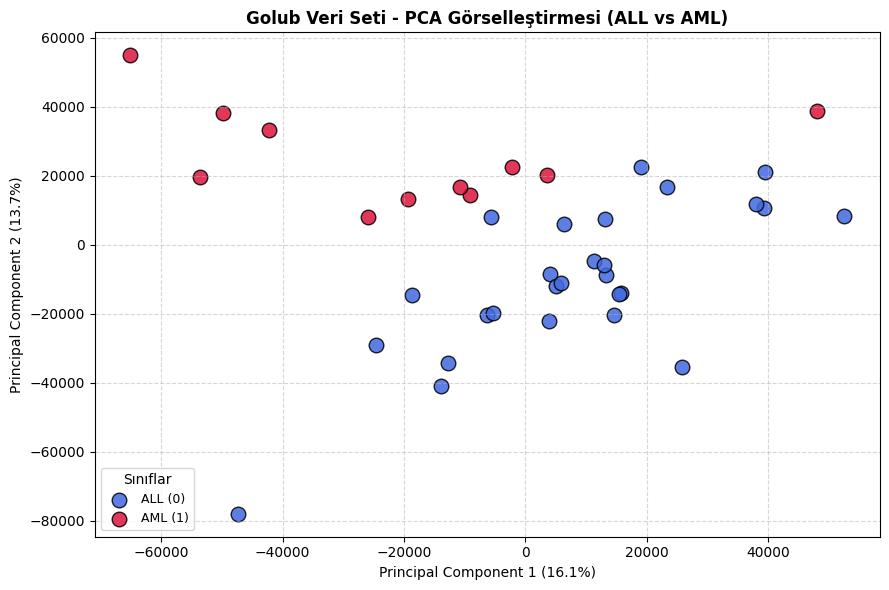

In [28]:
# 1. Gen verilerini (özellikleri) ve etiketleri ayıralım
# Son iki sütun 'patient' ve 'numeric_label' olduğu için onları çıkarıyoruz
X = train_final.drop(columns=['patient', 'numeric_label'])
y = train_final['numeric_label']

# 2. PCA ile 2 boyuta indirgeme
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Açıklanan varyans oranını yazdıralım
explained_variance = pca.explained_variance_ratio_
print(f"Açıklanan Varyans Oranı (PC1 + PC2): {sum(explained_variance)*100:.2f}%")

# 3. Görselleştirme
plt.figure(figsize=(9, 6))

plt.scatter(X_pca[y == 0, 0], X_pca[y == 0, 1], color='royalblue', s=110, alpha=0.85, edgecolor='black', linewidth=1, label='ALL (0)')
plt.scatter(X_pca[y == 1, 0], X_pca[y == 1, 1], color='crimson', s=110, alpha=0.85, edgecolor='black', linewidth=1, label='AML (1)')

plt.title('Golub Veri Seti - PCA Görselleştirmesi (ALL vs AML)', fontsize=12, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({explained_variance[0]*100:.1f}%)', fontsize=10)
plt.ylabel(f'Principal Component 2 ({explained_variance[1]*100:.1f}%)', fontsize=10)

plt.legend(title='Sınıflar', loc='lower left', fontsize=9)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

<Figure size 1200x800 with 0 Axes>

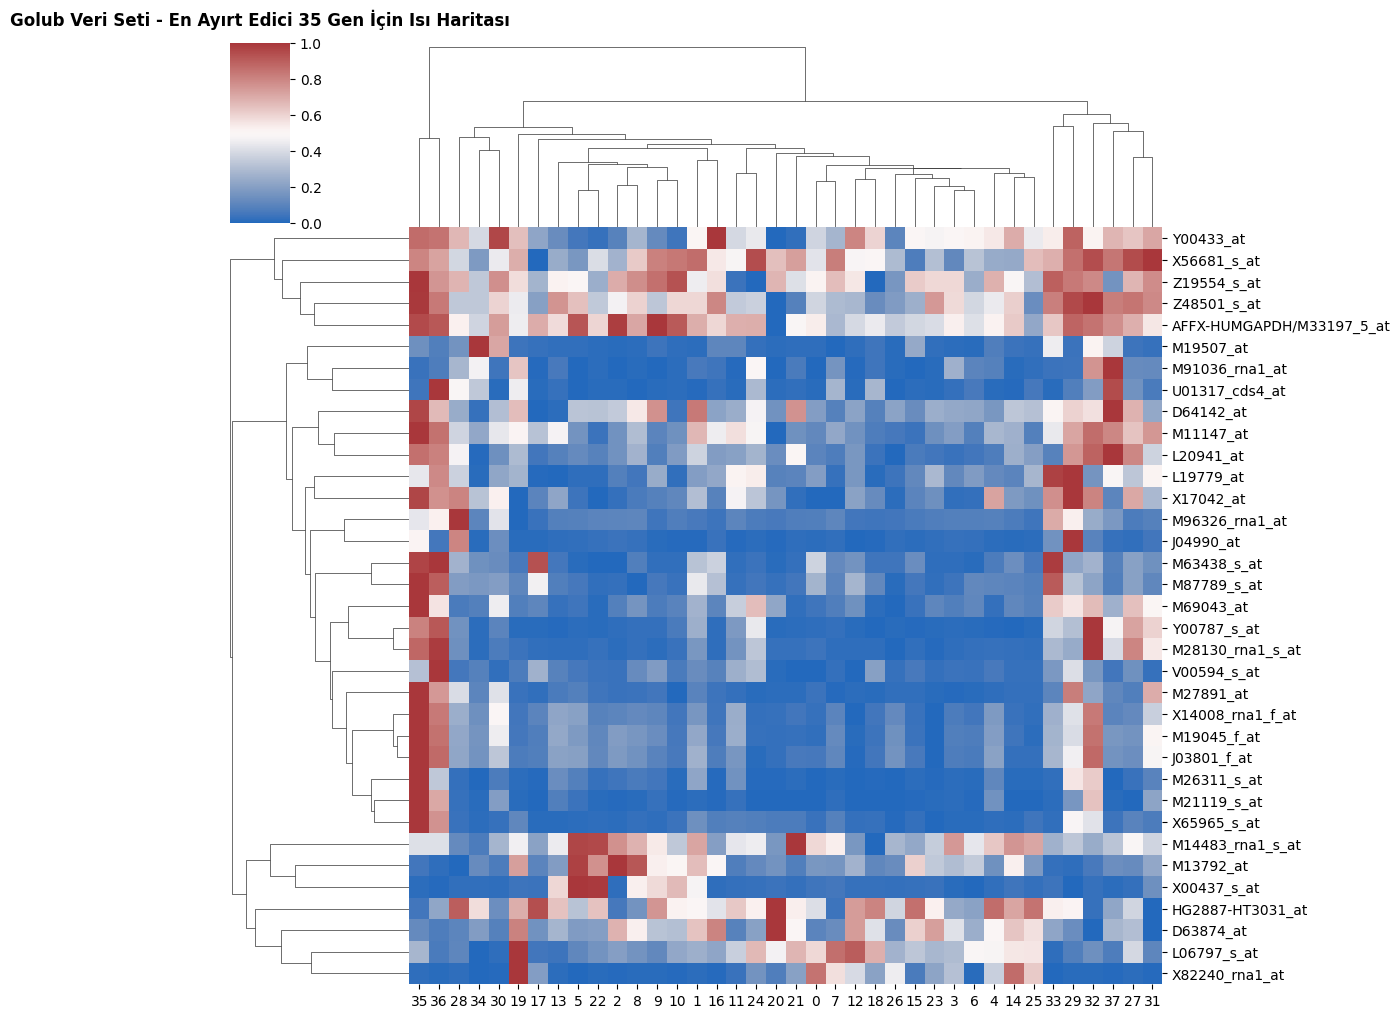

In [32]:
X = train_final.drop(columns=['patient', 'numeric_label'])
y = train_final['numeric_label']

mean_all = X[y == 0].mean()
mean_aml = X[y == 1].mean()

diff = (mean_all - mean_aml).abs()
top_genes = diff.nlargest(35).index

X_top35 = X[top_genes]

plt.figure(figsize=(12, 8))
sns.clustermap(
    X_top35.T,  # Genler satırda, hastalar sütunda olsun
    cmap='vlag',  # Isı haritası renk paleti (mavi-kırmızı tonları)
    standard_scale=0,  # Gen bazlı standartlaştırma (görselliği iyileştirir)
    col_cluster=True,  # Hastaları benzerliklerine göre kümele
    row_cluster=True,  # Genleri benzerliklerine göre kümele
    figsize=(12, 10)
)

plt.title("Golub Veri Seti - En Ayırt Edici 35 Gen İçin Isı Haritası", y=1.05, fontsize=12, fontweight='bold')
plt.show()